In [39]:
!pip install -q --upgrade ultralytics roboflow streamlit


In [40]:
!pip install -q --upgrade ultralytics roboflow gradio edge-tts

In [41]:
import os
import json
import time
import random
import asyncio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import gradio as gr
import edge_tts
from PIL import Image
from datetime import datetime
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow
from ultralytics import YOLO
import torch

print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")

CUDA Available: True
Active GPU: Tesla T4


In [42]:
from roboflow import Roboflow
API_KEY = "i0JtwGnr0NAMTPV1qmhq"
rf = Roboflow(api_key=API_KEY)
project = rf.workspace("zezoshosha80-gmail-com").project("road-damage-l1ju7-trj8d")
version = project.version(1)
dataset = version.download("yolo26", location="/kaggle/working/dataset")
print("Dataset successfully downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Dataset successfully downloaded to: /kaggle/working/dataset


In [43]:
!ls -la /kaggle/working/dataset

total 28
drwxr-xr-x 5 root root 4096 Oct 28 20:58 .
drwxr-xr-x 5 root root 4096 Oct 28 21:07 ..
-rw-r--r-- 1 root root  356 Oct 28 20:58 data.yaml
-rw-r--r-- 1 root root  882 Oct 28 20:58 README.roboflow.txt
drwxr-xr-x 4 root root 4096 Oct 28 20:58 test
drwxr-xr-x 4 root root 4096 Oct 28 20:58 train
drwxr-xr-x 4 root root 4096 Oct 28 20:58 valid


In [44]:
DATA_YAML           = "/kaggle/working/dataset/data.yaml"
EXPERIMENTS_DIR     = "/kaggle/working/experiments"
OUTPUTS_DIR         = "/kaggle/working/outputs"
RESULTS_JSON        = "/kaggle/working/outputs/results.json"
PLOTS_DIR           = "/kaggle/working/outputs/plots"
VAL_IMAGES_DIR      = "/kaggle/working/dataset/valid/images"
VAL_LABELS_DIR      = "/kaggle/working/dataset/valid/labels"
PREDICTIONS_DIR     = "/kaggle/working/outputs/predictions"
IOU_THRESHOLD       = 0.5
NUM_IMAGES_TO_SHOW  = 9
SEED                = 42
os.makedirs(OUTPUTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(PREDICTIONS_DIR, exist_ok=True)
CLASS_COLORS = {
    0: "#00E5FF",  
    1: "#FF1744", 
    2: "#FFEA00",  
    3: "#76FF03",  
    4: "#D500F9",  
}
DEFAULT_CORRECT_COLOR = "#FF007F"  
DEFAULT_WRONG_COLOR   = "#CCFF00"  

In [ ]:

MODELS = ["yolov8s.pt", "yolo11s.pt", "yolo26s.pt"]

TUNING_CONFIGS = {
    "yolov8s": {"epochs": 40, "batch": 16, "imgsz": 640, "lr0": 0.01,  "optimizer": "SGD"},
    "yolo11s": {"epochs": 40, "batch": 16, "imgsz": 640, "lr0": 0.005, "optimizer": "AdamW"},
    "yolo26s": {"epochs": 40, "batch": 16, "imgsz": 640, "lr0": 0.003, "optimizer": "auto"}
}

def train_one_model(weights_name: str) -> dict:
    model_name = weights_name.replace(".pt", "")
    cfg = TUNING_CONFIGS.get(model_name, {"epochs": 40, "batch": 16, "imgsz": 640, "lr0": 0.01, "optimizer": "auto"})
    run_name = f"{model_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
    
    print(f"\n{'='*25} Start Training: {model_name} {'='*25}")
    print(f"Hyperparameters: Epochs={cfg['epochs']} | Batch={cfg['batch']} | lr0={cfg['lr0']} | Optimizer={cfg['optimizer']}")

    model = YOLO(weights_name)
    model.train(
        data=DATA_YAML,
        epochs=cfg["epochs"],
        batch=cfg["batch"],
        imgsz=cfg["imgsz"],
        lr0=cfg["lr0"],
        optimizer=cfg["optimizer"],
        seed=SEED,
        project=EXPERIMENTS_DIR,
        name=run_name,
        verbose=True
    )
    
    best_weights_path = os.path.join(EXPERIMENTS_DIR, run_name, "weights", "best.pt")
    best_model = YOLO(best_weights_path)
    
    # استخراج المقاييس الرسمية عبر الـ Validation Set
    metrics = best_model.val(data=DATA_YAML)
    map50 = float(metrics.box.map50)
    map50_95 = float(metrics.box.map)
    precision = float(metrics.box.mp)
    recall = float(metrics.box.mr)
    model_size_mb = os.path.getsize(best_weights_path) / (1024 * 1024)
    sample_images = [f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    avg_inference_ms, fps = None, None
    
    if sample_images:
        sample_path = os.path.join(VAL_IMAGES_DIR, sample_images[0])
        is_yolo26 = "yolo26" in model_name
        predict_kwargs = {"nms": False} if is_yolo26 else {}
        
        best_model.predict(sample_path, verbose=False, **predict_kwargs)
        start = time.time()
        n_runs = 30
        for _ in range(n_runs):
            best_model.predict(sample_path, verbose=False, **predict_kwargs)
        elapsed = time.time() - start
        avg_inference_ms = (elapsed / n_runs) * 1000
        fps = 1000 / avg_inference_ms

    result = {
        "model_name": model_name,
        "best_weights_path": best_weights_path,
        "mAP50": round(map50, 4),
        "mAP50-95": round(map50_95, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "model_size_mb": round(model_size_mb, 2),
        "avg_inference_ms": round(avg_inference_ms, 2) if avg_inference_ms else None,
        "fps": round(fps, 2) if fps else None,
        "lr0": cfg["lr0"],
        "optimizer": cfg["optimizer"]
    }
    
    print(f"Done {model_name}: mAP50={result['mAP50']} | mAP50-95={result['mAP50-95']} | Size={result['model_size_mb']}MB | FPS={result['fps']}")
    return result

def train_all_models() -> list:
    results = []  
    for weights_name in MODELS:
        res = train_one_model(weights_name)
        results.append(res)
    return results

def print_comparison_table(results: list):
    print("\n" + "="*85)
    print("=== Road Damage Detection Comparison Table ===")
    print("="*85)
    header = f"{'Model':<12}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['model_name']:<12}{r['mAP50']:<10}{r['mAP50-95']:<12}"
            f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
        )
    print("-" * len(header))
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"Best Model for Deployment (highest mAP50-95): {best['model_name']}")
    print(f"Weights path: {best['best_weights_path']}")
    print("="*85)

all_results = train_all_models()
print_comparison_table(all_results)

with open(RESULTS_JSON, "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

print(f"Saved results to: {RESULTS_JSON}")

In [61]:
!tail -n 20 /kaggle/working/experiments/yolo26s_20261028_230255/results.csv

epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
1,88.7641,1.88731,5.68209,0.01901,0.39706,0.21405,0.16277,0.07908,2.04402,3.66244,0.03007,0.000302016,0.000302016,0.000302016
2,175.429,1.91156,2.92892,0.01971,0.33064,0.21485,0.19276,0.09198,1.99621,2.97677,0.02927,0.000590042,0.000590042,0.000590042
3,261.711,1.91376,2.7661,0.01961,0.37296,0.21061,0.17254,0.07596,2.07111,3.35892,0.03057,0.000863069,0.000863069,0.000863069
4,347.587,1.91538,2.67039,0.02006,0.29697,0.22351,0.19828,0.09554,2.04323,2.81249,0.0298,0.000841507,0.000841507,0.000841507
5,433.481,1.90744,2.57937,0.01944,0.24054,0.24353,0.21963,0.10893,2.06089,2.82371,0.03055,0.000819009,0.000819009,0.000819009
6,519.186,1.87969,2.49537,0.01899,0.33487,0.29432,0.27516,0.14345,2.01629,2.62133,0.02949,0.000796511,0.000796511,0.000796511
7,604.827,1.86379,2.43068,0.01857,0.52931,0.28431,0.2746

In [62]:
import os
import glob
import json
import time
from ultralytics import YOLO


experiments = sorted(glob.glob("/kaggle/working/experiments/*/weights/best.pt"))

results = []
sample_images = [f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
sample_path = os.path.join(VAL_IMAGES_DIR, sample_images[0]) if sample_images else None

print(f"Found {len(experiments)} trained models. Evaluating final metrics...\n")

for best_weights_path in experiments:

    folder_name = best_weights_path.split("/")[-3]
    model_name = folder_name.split("_")[0]
    
    print(f"Evaluating: {model_name} ({folder_name})...")
    model = YOLO(best_weights_path)
    

    metrics = model.val(data=DATA_YAML, verbose=False)
    map50 = float(metrics.box.map50)
    map50_95 = float(metrics.box.map)
    precision = float(metrics.box.mp)
    recall = float(metrics.box.mr)
    model_size_mb = os.path.getsize(best_weights_path) / (1024 * 1024)
    
    # قياس الـ FPS
    avg_inference_ms, fps = None, None
    if sample_path:
        is_yolo26 = "yolo26" in model_name
        predict_kwargs = {"nms": False} if is_yolo26 else {}
        
        # Warmup
        model.predict(sample_path, verbose=False, **predict_kwargs)
        start = time.time()
        n_runs = 30
        for _ in range(n_runs):
            model.predict(sample_path, verbose=False, **predict_kwargs)
        elapsed = time.time() - start
        avg_inference_ms = (elapsed / n_runs) * 1000
        fps = 1000 / avg_inference_ms

    results.append({
        "model_name": model_name,
        "best_weights_path": best_weights_path,
        "mAP50": round(map50, 4),
        "mAP50-95": round(map50_95, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "model_size_mb": round(model_size_mb, 2),
        "avg_inference_ms": round(avg_inference_ms, 2) if avg_inference_ms else None,
        "fps": round(fps, 2) if fps else None
    })

print("\n" + "="*85)
print("=== Road Damage Detection Comparison Table ===")
print("="*85)
header = f"{'Model':<12}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
print(header)
print("-" * len(header))
for r in results:
    print(
        f"{r['model_name']:<12}{r['mAP50']:<10}{r['mAP50-95']:<12}"
        f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
    )
print("-" * len(header))
best = max(results, key=lambda r: r["mAP50-95"])
print(f"Best Model for Deployment: {best['model_name']}")
print(f"Weights path: {best['best_weights_path']}")
print("="*85)

# حفظ النتائج في results.json
with open(RESULTS_JSON, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print(f"\nSaved final results to: {RESULTS_JSON}")

Found 3 trained models. Evaluating final metrics...

Evaluating: yolo11s (yolo11s_20261028_221020)...
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,509 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1648.1±876.8 MB/s, size: 76.6 KB)
val: Scanning /kaggle/working/dataset/valid/labels.cache... 1146 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 1146/1146 57.9Mit/s 0.0s
val: /kaggle/working/dataset/valid/images/21_jpg.rf.c731b007cc2a3a8ad5f8c38699f0ef8b.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/dataset/valid/images/img-243-_jpg.rf.3b930402f9ac33c999be09920f6d577d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/dataset/valid/images/img-249-_jpg.rf.36bb217ac9a7e18532cc2a353383a74d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/worki

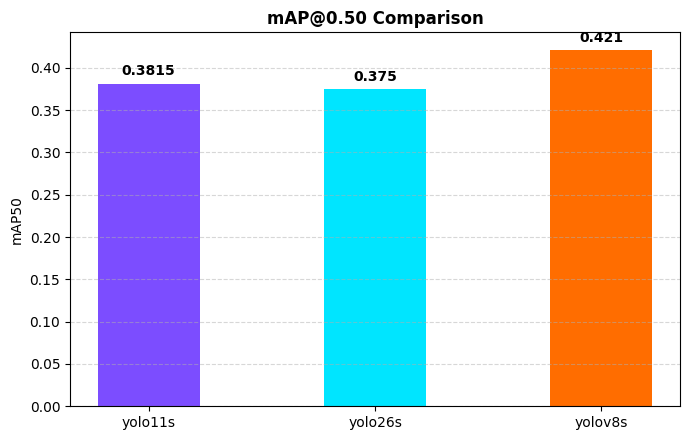

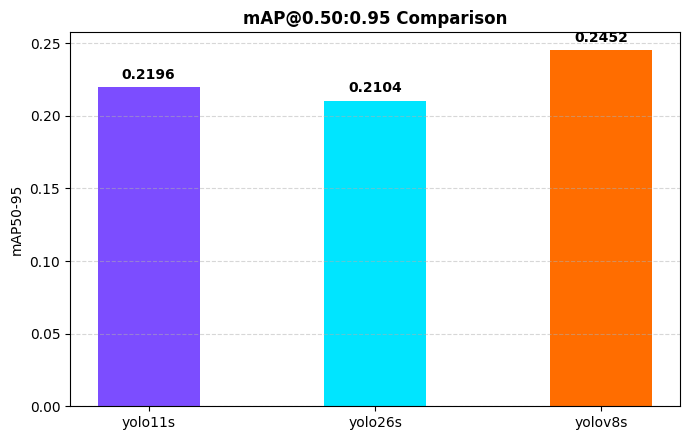

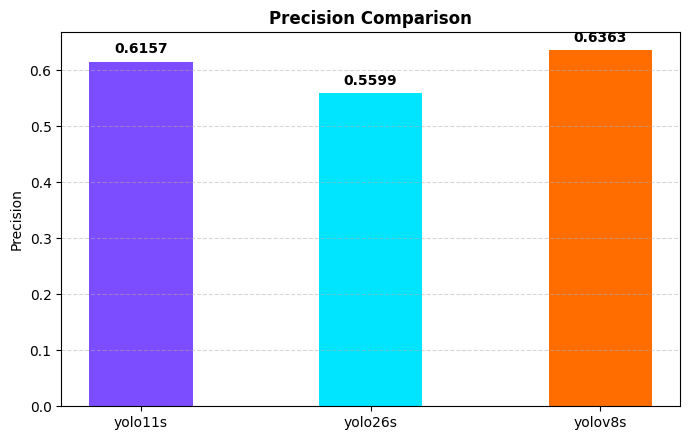

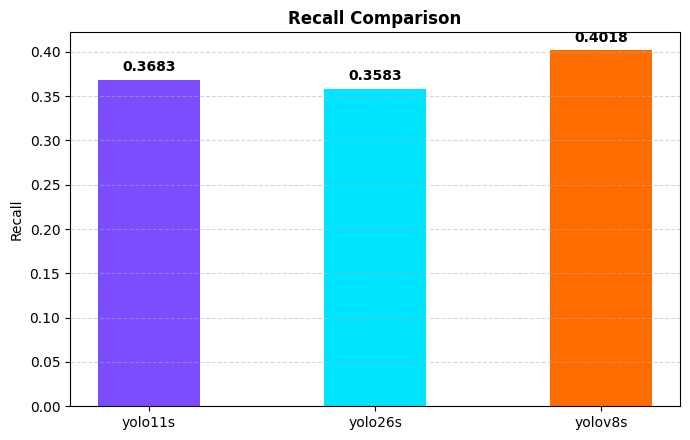

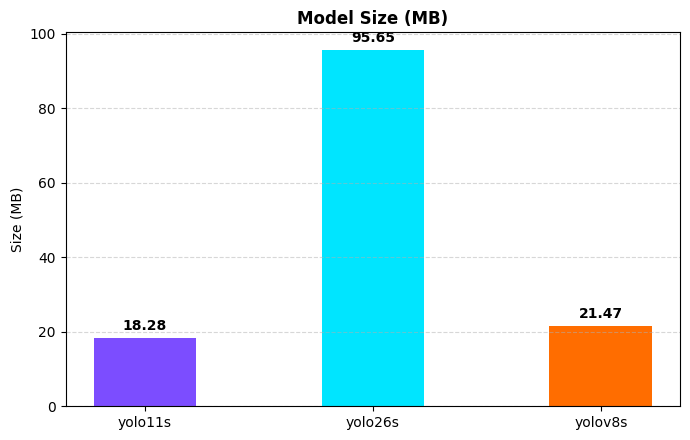

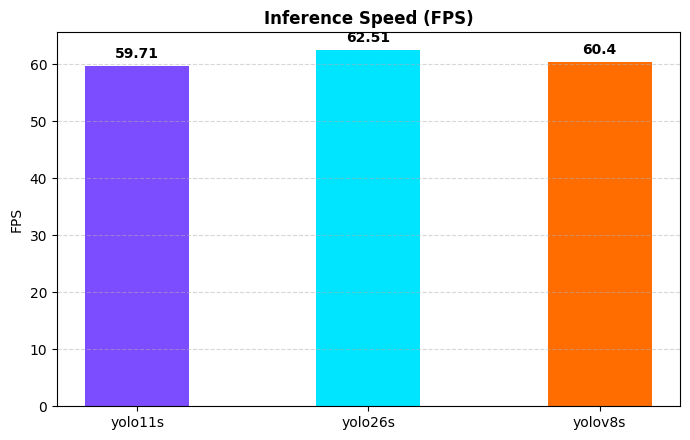

In [66]:
import os
import json
import matplotlib.pyplot as plt

OUTPUTS_DIR = "/kaggle/working/outputs"
PLOTS_DIR   = "/kaggle/working/outputs/plots"
RESULTS_JSON = "/kaggle/working/outputs/results.json"
os.makedirs(PLOTS_DIR, exist_ok=True)

with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    results = json.load(f)

def generate_bar_chart(data: list, metric_key: str, title: str, ylabel: str, filename: str):
    names = [r["model_name"] for r in data]
    values = [r[metric_key] for r in data]

    plt.figure(figsize=(7, 4.5))
    bars = plt.bar(names, values, color=["#7C4DFF", "#00E5FF", "#FF6D00"], width=0.45)
    plt.title(title, fontsize=12, fontweight="bold")
    plt.ylabel(ylabel)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    for bar, val in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (max(values) * 0.015),
            str(val),
            ha="center",
            va="bottom",
            fontweight="bold"
        )

    plt.tight_layout()
    save_path = os.path.join(PLOTS_DIR, filename)
    plt.savefig(save_path, dpi=200)
    plt.show()

generate_bar_chart(results, "mAP50", "mAP@0.50 Comparison", "mAP50", "map50.png")
generate_bar_chart(results, "mAP50-95", "mAP@0.50:0.95 Comparison", "mAP50-95", "map50_95.png")
generate_bar_chart(results, "precision", "Precision Comparison", "Precision", "precision.png")
generate_bar_chart(results, "recall", "Recall Comparison", "Recall", "recall.png")
generate_bar_chart(results, "model_size_mb", "Model Size (MB)", "Size (MB)", "model_size.png")
generate_bar_chart(results, "fps", "Inference Speed (FPS)", "FPS", "fps.png")

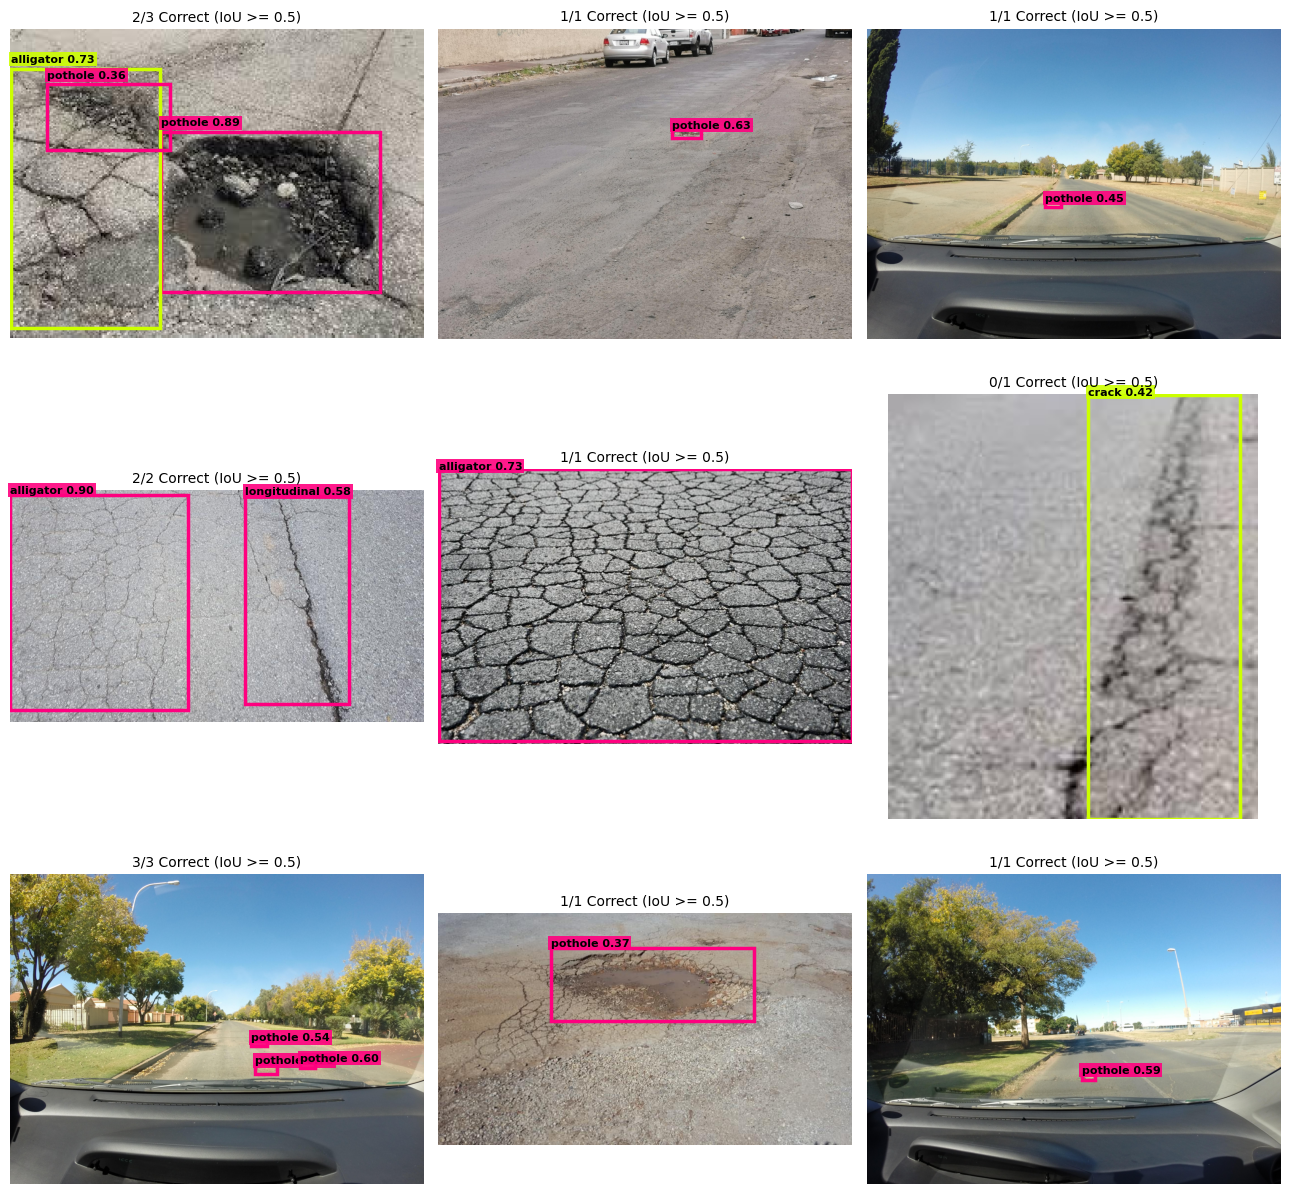

Validation grid saved: /kaggle/working/outputs/predictions/validation_grid.png


In [67]:
import os
import random
import json
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO

VAL_IMAGES_DIR  = "/kaggle/working/dataset/valid/images"
VAL_LABELS_DIR  = "/kaggle/working/dataset/valid/labels"
PREDICTIONS_DIR = "/kaggle/working/outputs/predictions"
IOU_THRESHOLD   = 0.5
NUM_IMAGES      = 9
os.makedirs(PREDICTIONS_DIR, exist_ok=True)


CORRECT_COLOR = "#FF007F"  
WRONG_COLOR   = "#CCFF00"  


with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    eval_res = json.load(f)
best_info = max(eval_res, key=lambda r: r["mAP50-95"])
deploy_model = YOLO(best_info["best_weights_path"])
class_names = deploy_model.names

def compute_iou(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0.0

def load_gt(lbl_path, w, h):
    boxes = []
    if not os.path.exists(lbl_path): return boxes
    with open(lbl_path, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) == 5:
                cls_id, xc, yc, bw, bh = map(float, p)
                boxes.append([int(cls_id), (xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h])
    return boxes

all_imgs = [f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
selected = random.sample(all_imgs, min(NUM_IMAGES, len(all_imgs)))

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
axes = axes.flatten()

for i, img_name in enumerate(selected):
    ip = os.path.join(VAL_IMAGES_DIR, img_name)
    lp = os.path.join(VAL_LABELS_DIR, os.path.splitext(img_name)[0] + ".txt")

    with Image.open(ip) as im:
        iw, ih = im.size

    preds = deploy_model.predict(ip, verbose=False)[0]
    pred_boxes = [[int(cls), *b, conf] for b, cls, conf in zip(preds.boxes.xyxy.tolist(), preds.boxes.cls.tolist(), preds.boxes.conf.tolist())]
    gts = load_gt(lp, iw, ih)

    used_gt = set()
    evaluated = []
    for pred in pred_boxes:
        pc, px1, py1, px2, py2, conf = pred
        best_iou, b_idx = 0.0, -1
        for idx, gt in enumerate(gts):
            if idx in used_gt or gt[0] != pc: continue
            iou = compute_iou([px1, py1, px2, py2], gt[1:])
            if iou > best_iou:
                best_iou, b_idx = iou, idx
        is_corr = best_iou >= IOU_THRESHOLD
        if is_corr: used_gt.add(b_idx)
        evaluated.append({"class_id": pc, "box": [px1, py1, px2, py2], "conf": conf, "correct": is_corr})

    ax = axes[i]
    ax.imshow(Image.open(ip))
    ax.axis("off")

    for p in evaluated:
        x1, y1, x2, y2 = p["box"]
        color = CORRECT_COLOR if p["correct"] else WRONG_COLOR
        label = f"{class_names.get(p['class_id'], p['class_id'])} {p['conf']:.2f}"
        
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2.5, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, max(y1 - 4, 0), label, color="black", fontsize=8, fontweight="bold",
                bbox=dict(facecolor=color, alpha=0.9, pad=1.5, edgecolor="none"))

    correct_count = sum(1 for p in evaluated if p["correct"])
    ax.set_title(f"{correct_count}/{len(evaluated)} Correct (IoU >= {IOU_THRESHOLD})", fontsize=10)

plt.tight_layout()
grid_path = os.path.join(PREDICTIONS_DIR, "validation_grid.png")
plt.savefig(grid_path, dpi=200)
plt.show()
print(f"Validation grid saved: {grid_path}")

In [74]:
import cv2
import json
import asyncio
import numpy as np
import gradio as gr
import edge_tts
from PIL import Image
from ultralytics import YOLO

# 1. تحميل أفضل نموذج تم حفظه
RESULTS_JSON = "/kaggle/working/outputs/results.json"
with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    best_entry = max(json.load(f), key=lambda x: x["mAP50-95"])
live_model = YOLO(best_entry["best_weights_path"])

# لوحة ألوان نيون متباينة لرسم المربعات (BGR لـ OpenCV)
NEON_PALETTE = [
    (255, 229, 0),    # Electric Cyan
    (0, 109, 255),    # Vibrant Orange
    (118, 230, 0),    # Neon Lime
    (255, 31, 101),   # Ultraviolet
    (0, 214, 255),    # Golden Amber
    (255, 0, 127),    # Hot Pink
    (128, 255, 0)     # Emerald Green
]

# 2. توليد الصوت البشري الطبيعي بالإنجليزية
async def generate_english_voice(text: str, path: str = "/kaggle/working/alert.mp3") -> str:
    comm = edge_tts.Communicate(text, voice="en-US-AriaNeural", rate="+10%")
    await comm.save(path)
    return path

# 3. معالجة واستدلال الصورة
def run_road_inspection(input_image, conf_score):
    if input_image is None:
        return None, "⚠️ Please upload an image or capture a frame first.", None

    # تحجيم الصورة لتسريع المعالجة والرفع
    max_dimension = 1024
    w, h = input_image.size
    if max(w, h) > max_dimension:
        scale = max_dimension / max(w, h)
        input_image = input_image.resize((int(w * scale), int(h * scale)), Image.Resampling.LANCZOS)

    img_bgr = cv2.cvtColor(np.array(input_image), cv2.COLOR_RGB2BGR)
    detections = live_model.predict(source=img_bgr, conf=conf_score, verbose=False)[0]
    
    found_labels = []
    if detections.boxes is not None and len(detections.boxes) > 0:
        for box in detections.boxes:
            cid = int(box.cls[0])
            conf = float(box.conf[0])
            cname = live_model.names[cid]
            found_labels.append(cname)
            
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            color = NEON_PALETTE[cid % len(NEON_PALETTE)]
            
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, 3)
            
            tag = f"{cname} {conf:.1%}"
            (tw, th), _ = cv2.getTextSize(tag, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
            cv2.rectangle(img_bgr, (x1, max(y1 - 25, 0)), (x1 + tw + 6, max(y1, 25)), color, -1)
            cv2.putText(img_bgr, tag, (x1 + 3, max(y1 - 7, 18)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2)

        annotated_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        count = len(detections.boxes)
        unique_damages = ", ".join(sorted(set(found_labels)))
        
        speech_text = f"Caution! Detected {count} road damages: {unique_damages}."
        summary = f"🚨 {count} damage(s) detected: {unique_damages}"
    else:
        annotated_rgb = np.array(input_image)
        speech_text = "The road surface is clear. Safe journey."
        summary = "✅ Road surface looks safe and clear."

    audio_file = "/kaggle/working/alert.mp3"
    asyncio.run(generate_english_voice(speech_text, audio_file))
    
    return annotated_rgb, summary, audio_file

# 4. التنسيق الجمالي عبر CSS
custom_css = """
.gradio-container {
    font-family: 'Segoe UI', system-ui, -apple-system, sans-serif !important;
}
.header-box {
    text-align: center;
    padding: 20px 10px;
    background: linear-gradient(135deg, rgba(30, 41, 59, 0.8), rgba(15, 23, 42, 0.9));
    border-radius: 12px;
    border: 1px solid rgba(255, 255, 255, 0.1);
    margin-bottom: 20px;
}
.header-box h1 {
    color: #38bdf8;
    margin-bottom: 6px;
    font-weight: 700;
}
.header-box p {
    color: #94a3b8;
    font-size: 0.95rem;
    margin: 0;
}
button.primary-btn {
    background: linear-gradient(90deg, #0284c7, #2563eb) !important;
    border: none !important;
    font-weight: 600 !important;
    letter-spacing: 0.5px;
}
"""

# بناء الواجهة (بدون تمرير theme أو css هنا)
with gr.Blocks(title="Road Damage AI") as app:
    with gr.Column(elem_classes=["header-box"]):
        gr.Markdown(
            """
            # 🛣️ Road Damage AI Surveillance System
            Real-time asphalt condition assessment with automated neural voice alerts.
            """
        )
    
    with gr.Row():
        with gr.Column(scale=1):
            camera_in = gr.Image(
                sources=["upload", "webcam"],
                type="pil",
                label="Input Source (Upload or Live Webcam)"
            )
            conf_bar = gr.Slider(
                minimum=0.1,
                maximum=1.0,
                value=0.35,
                step=0.05,
                label="Detection Confidence Threshold"
            )
            submit_btn = gr.Button("Analyze Road 🚀", variant="primary", elem_classes=["primary-btn"])
            
        with gr.Column(scale=1):
            image_out = gr.Image(
                type="numpy",
                label="Visual Detections (Neon Overlays)"
            )
            text_out = gr.Textbox(
                label="Inspection Status",
                placeholder="Awaiting road image...",
                interactive=False
            )
            audio_out = gr.Audio(
                label="Neural Voice Assistant",
                autoplay=True
            )

    submit_btn.click(
        fn=run_road_inspection,
        inputs=[camera_in, conf_bar],
        outputs=[image_out, text_out, audio_out]
    )

# تمرير theme و css داخل launch() متوافقاً مع Gradio 6.0
app.launch(
    theme=gr.themes.Default(primary_hue="sky", neutral_hue="slate"),
    css=custom_css,
    share=True,
    debug=False
)

* Running on local URL:  http://127.0.0.1:7864
* Running on public URL: https://1ddc38a67c8c218fde.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [75]:
import cv2
import json
import asyncio
import numpy as np
import gradio as gr
import edge_tts
from PIL import Image
from ultralytics import YOLO

# 1. إغلاق أي جلسات Gradio مفتوحة في الخلفية
gr.close_all()

# 2. تحميل أفضل نموذج
RESULTS_JSON = "/kaggle/working/outputs/results.json"
with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    best_entry = max(json.load(f), key=lambda x: x["mAP50-95"])
live_model = YOLO(best_entry["best_weights_path"])

# ألوان النيون (BGR)
NEON_PALETTE = [
    (255, 229, 0),    # Electric Cyan
    (0, 109, 255),    # Vibrant Orange
    (118, 230, 0),    # Neon Lime
    (255, 31, 101),   # Ultraviolet
    (0, 214, 255),    # Golden Amber
    (255, 0, 127),    # Hot Pink
    (128, 255, 0)     # Emerald Green
]

# 3. محرك الصوت الإنجليزي السريع
async def generate_english_voice(text: str, path: str = "/kaggle/working/alert.mp3") -> str:
    comm = edge_tts.Communicate(text, voice="en-US-AriaNeural", rate="+10%")
    await comm.save(path)
    return path

# 4. دالة المعالجة والاستدلال
def run_road_inspection(input_image, conf_score):
    if input_image is None:
        return None, "⚠️ Please upload an image or capture a frame first.", None

    max_dimension = 1024
    w, h = input_image.size
    if max(w, h) > max_dimension:
        scale = max_dimension / max(w, h)
        input_image = input_image.resize((int(w * scale), int(h * scale)), Image.Resampling.LANCZOS)

    img_bgr = cv2.cvtColor(np.array(input_image), cv2.COLOR_RGB2BGR)
    detections = live_model.predict(source=img_bgr, conf=conf_score, verbose=False)[0]
    
    found_labels = []
    if detections.boxes is not None and len(detections.boxes) > 0:
        for box in detections.boxes:
            cid = int(box.cls[0])
            conf = float(box.conf[0])
            cname = live_model.names[cid]
            found_labels.append(cname)
            
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            color = NEON_PALETTE[cid % len(NEON_PALETTE)]
            
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, 3)
            tag = f"{cname} {conf:.1%}"
            (tw, th), _ = cv2.getTextSize(tag, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
            cv2.rectangle(img_bgr, (x1, max(y1 - 25, 0)), (x1 + tw + 6, max(y1, 25)), color, -1)
            cv2.putText(img_bgr, tag, (x1 + 3, max(y1 - 7, 18)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2)

        annotated_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        count = len(detections.boxes)
        unique_damages = ", ".join(sorted(set(found_labels)))
        speech_text = f"Caution! Detected {count} road damages: {unique_damages}."
        summary = f"🚨 {count} damage(s) detected: {unique_damages}"
    else:
        annotated_rgb = np.array(input_image)
        speech_text = "The road surface is clear. Safe journey."
        summary = "✅ Road surface looks safe and clear."

    audio_file = "/kaggle/working/alert.mp3"
    asyncio.run(generate_english_voice(speech_text, audio_file))
    return annotated_rgb, summary, audio_file

# 5. التنسيق الجمالي
custom_css = """
.header-box {
    text-align: center;
    padding: 20px 10px;
    background: linear-gradient(135deg, rgba(30, 41, 59, 0.8), rgba(15, 23, 42, 0.9));
    border-radius: 12px;
    border: 1px solid rgba(255, 255, 255, 0.1);
    margin-bottom: 20px;
}
.header-box h1 {
    color: #38bdf8;
    margin-bottom: 6px;
    font-weight: 700;
}
.header-box p {
    color: #94a3b8;
    font-size: 0.95rem;
    margin: 0;
}
"""

with gr.Blocks(title="Road Damage AI") as app:
    with gr.Column(elem_classes=["header-box"]):
        gr.Markdown(
            """
            # 🛣️ Road Damage AI Surveillance System
            Real-time asphalt condition assessment with automated neural voice alerts.
            """
        )
    
    with gr.Row():
        with gr.Column(scale=1):
            camera_in = gr.Image(
                sources=["upload", "webcam"],
                type="pil",
                label="Input Source (Upload or Live Webcam)"
            )
            conf_bar = gr.Slider(
                minimum=0.1,
                maximum=1.0,
                value=0.35,
                step=0.05,
                label="Detection Confidence Threshold"
            )
            submit_btn = gr.Button("Analyze Road 🚀", variant="primary")
            
        with gr.Column(scale=1):
            image_out = gr.Image(type="numpy", label="Visual Detections (Neon Overlays)")
            text_out = gr.Textbox(label="Inspection Status", placeholder="Awaiting road image...", interactive=False)
            audio_out = gr.Audio(label="Neural Voice Assistant", autoplay=True)

    submit_btn.click(
        fn=run_road_inspection,
        inputs=[camera_in, conf_bar],
        outputs=[image_out, text_out, audio_out]
    )

# تشغيل التطبيق مع إبقاء الجلسة نشطة
app.launch(
    theme=gr.themes.Default(primary_hue="sky", neutral_hue="slate"),
    css=custom_css,
    share=True,
    inline=False
)

Closing server running on port: 7864
Closing server running on port: 7863
Closing server running on port: 7862
Closing server running on port: 7860
Closing server running on port: 7861
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://d97184edd33582a8db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
